# Results: does the greedy hint-removal sweep recover the easy-to-hard transition?

**Question** (the first real test of this exploration): do random-regular-graph DD
Sudoku instances show the fast/slow reasoning-depth transition the slides claim, at
`q=4, d=5` (`rho_c~0.46`, claimed continuous) and `d=7` (`rho_c~0.27`, claimed
discontinuous)? See `SUDOKU_DD.md` for the full model.

**Answer: yes for `d=7`, not yet for `d=5`.** `d=7` shows a sharp jump in the
`T ~ N^gamma(rho)` growth exponent right at the claimed `rho_c`. `d=5` never reaches far
enough below its own `rho_c` to show the same thing -- greedy hint removal hits a hard,
very reproducible floor just above it, exactly the open problem flagged in the handoff
doc before this sweep ever ran.

**Data provenance.** Commit `f233fcf`. Sweep: `q=4, d in {4,5,6,7,8}`, 7 slide `N`
values (996 to 49992), 24 seeds each = 840 `(d,N,seed)` runs, Slurm job `47921119`
(single job, 16-way process pool, completed in 4m31s). Each `(d,N,seed)` is one
`np.random.default_rng([q,d,N,seed])`-seeded greedy removal path
(`spin_gnn.sudoku_dd.removal_path`) from `rho=1` down to wherever no further hint can
be removed. Output: `$SCRATCH/spin_gnn/sudoku_dd_results/q4_d{d}_N{N}_s{seed}.npz`.

In [1]:
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

INK = {"surface": "#fcfcfb", "primary": "#0b0b0b", "secondary": "#52514e",
       "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7"}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams["font.family"] = "sans-serif"


def style_axis(ax):
    ax.set_facecolor(INK["surface"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK["axis"])
    ax.spines["bottom"].set_color(INK["axis"])
    ax.tick_params(colors=INK["muted"])
    ax.grid(True, color=INK["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.title.set_color(INK["primary"])


RESULTS_DIR = Path(os.environ["SCRATCH"]) / "spin_gnn" / "sudoku_dd_results"
RHO_C = {5: 0.46, 7: 0.27}


def load_d(d):
    files = sorted(glob.glob(str(RESULTS_DIR / f"q4_d{d}_N*.npz")))
    by_n = {}
    for f in files:
        with np.load(f) as data:
            record = {"N": int(data["N"]), "rho_grid": data["rho_grid"],
                      "rho_min": float(data["rho_min"]), "T": data["T"].copy()}
        by_n.setdefault(record["N"], []).append(record)
    return by_n


data = {d: load_d(d) for d in (5, 7)}
for d, by_n in data.items():
    print(f"d={d}: {sum(len(v) for v in by_n.values())} runs over N={sorted(by_n)}")

d=5: 168 runs over N=[996, 2028, 4140, 8436, 17196, 35028, 49992]
d=7: 168 runs over N=[996, 2028, 4140, 8436, 17196, 35028, 49992]


## Metrics table: where does greedy removal get stuck (`rho_min`)?

Mean +- range of `rho_min` (the greedy path's own endpoint -- no further hint is
removable) over all 24 seeds per `N`, compared to the slides' claimed `rho_c`.

In [2]:
for d in (5, 7):
    print(f"--- d={d} (slides' rho_c = {RHO_C[d]}) ---")
    for n in sorted(data[d]):
        mins = [r["rho_min"] for r in data[d][n]]
        print(f"  N={n:6d}  rho_min: mean={np.mean(mins):.4f}  range=[{min(mins):.4f}, {max(mins):.4f}]")
    print()

--- d=5 (slides' rho_c = 0.46) ---
  N=   996  rho_min: mean=0.4756  range=[0.4578, 0.4980]
  N=  2028  rho_min: mean=0.4780  range=[0.4571, 0.4980]
  N=  4140  rho_min: mean=0.4768  range=[0.4659, 0.4843]
  N=  8436  rho_min: mean=0.4784  range=[0.4680, 0.4874]
  N= 17196  rho_min: mean=0.4779  range=[0.4739, 0.4840]
  N= 35028  rho_min: mean=0.4777  range=[0.4738, 0.4810]
  N= 49992  rho_min: mean=0.4778  range=[0.4740, 0.4820]

--- d=7 (slides' rho_c = 0.27) ---
  N=   996  rho_min: mean=0.2271  range=[0.2129, 0.2480]
  N=  2028  rho_min: mean=0.2269  range=[0.2120, 0.2436]
  N=  4140  rho_min: mean=0.2270  range=[0.2208, 0.2336]
  N=  8436  rho_min: mean=0.2259  range=[0.2216, 0.2323]
  N= 17196  rho_min: mean=0.2261  range=[0.2245, 0.2294]
  N= 35028  rho_min: mean=0.2260  range=[0.2233, 0.2295]
  N= 49992  rho_min: mean=0.2255  range=[0.2235, 0.2278]



## Key plot 1: T/log(N) vs rho, several N overlaid

Fast phase -> curves roughly flat/collapsed across N; slow phase -> curves fan out and
grow with N. `d=7` should show both; `d=5` only shows the fast side (data ends at its
`rho_min` floor, above `rho_c`).

/tmp/ipykernel_15859/2129174525.py:12: RuntimeWarning: Mean of empty slice
  mean_t = np.nanmean(t_stack, axis=0)


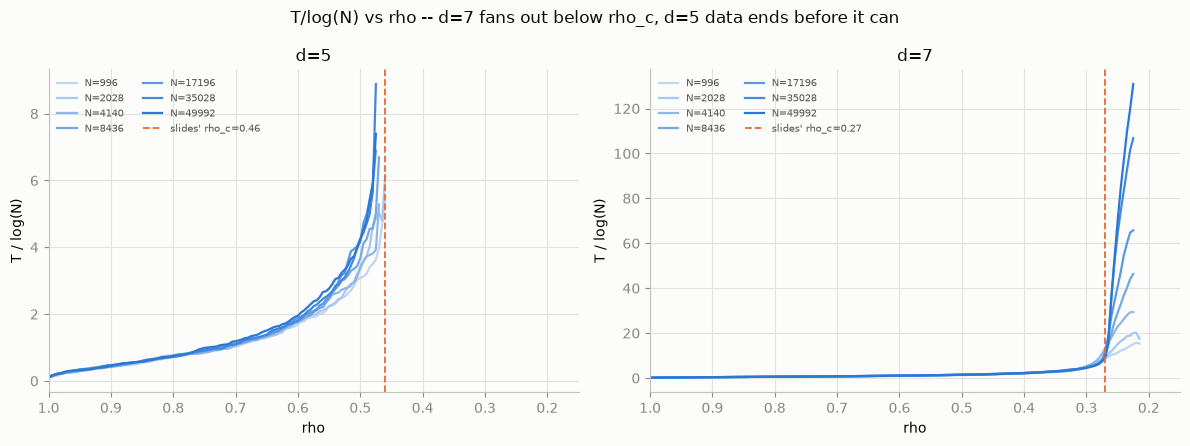

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.patch.set_facecolor(INK["surface"])

for ax, d in zip(axes, (5, 7)):
    by_n = data[d]
    ns = sorted(by_n)
    rho_grid = by_n[ns[0]][0]["rho_grid"]
    shades = np.linspace(0.3, 1.0, len(ns))
    for n, shade in zip(ns, shades):
        t_stack = np.array([r["T"] for r in by_n[n]])
        with np.errstate(invalid="ignore"):
            mean_t = np.nanmean(t_stack, axis=0)
        color = tuple(np.array(plt.matplotlib.colors.to_rgb(CATEGORICAL[0])) * shade +
                      np.array([1, 1, 1]) * (1 - shade))
        ax.plot(rho_grid, mean_t / np.log(n), color=color, lw=1.6, label=f"N={n}")
    ax.axvline(RHO_C[d], color=CATEGORICAL[1], linestyle="--", lw=1.3, label=f"slides' rho_c={RHO_C[d]}")
    ax.set_xlim(1.0, 0.15)
    ax.set_xlabel("rho")
    ax.set_ylabel("T / log(N)")
    ax.set_title(f"d={d}", color=INK["primary"])
    ax.legend(frameon=False, labelcolor=INK["secondary"], fontsize=7, ncol=2)
    style_axis(ax)
fig.suptitle("T/log(N) vs rho -- d=7 fans out below rho_c, d=5 data ends before it can", color=INK["primary"])
fig.tight_layout()
plt.show()

## Key plot 2: gamma(rho) -- the growth exponent, `log(T) ~ gamma(rho) * log(N)`

Fit a line to `log(mean T)` vs `log(N)` at each `rho` (using only `rho` where every `N`
still has enough valid seeds). `gamma ~ 0` = fast phase (sub-power-law, `T~log N`);
`gamma` growing = slow phase. This is the clearest single signal of the transition.

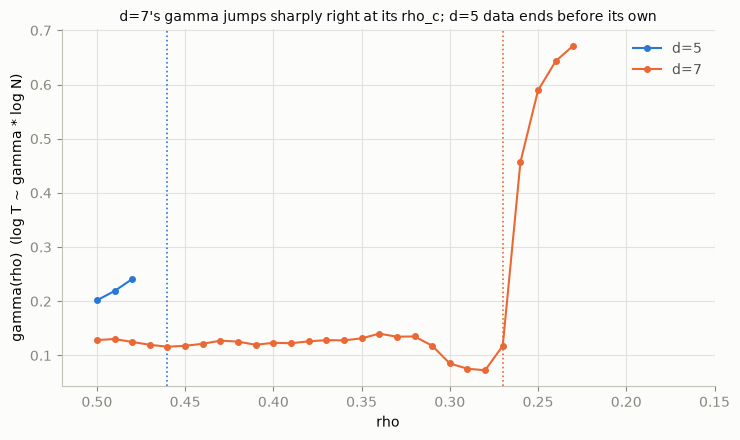

In [4]:
def gamma_curve(d, probe_rhos, min_seeds=5):
    by_n = data[d]
    ns = sorted(by_n)
    rho_grid = by_n[ns[0]][0]["rho_grid"]
    rhos_out, gammas_out = [], []
    for rho in probe_rhos:
        idx = int(np.argmin(np.abs(rho_grid - rho)))
        log_ns, log_ts = [], []
        for n in ns:
            t_vals = np.array([r["T"][idx] for r in by_n[n]])
            valid = ~np.isnan(t_vals) & (t_vals > 0)
            if valid.sum() < min_seeds:
                continue
            log_ns.append(np.log(n))
            log_ts.append(np.log(np.mean(t_vals[valid])))
        if len(log_ns) < 3:
            continue
        slope, _ = np.polyfit(log_ns, log_ts, 1)
        rhos_out.append(rho_grid[idx])
        gammas_out.append(slope)
    return np.array(rhos_out), np.array(gammas_out)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
fig.patch.set_facecolor(INK["surface"])
probe = np.arange(0.5, 0.15, -0.01)
for d, color in zip((5, 7), CATEGORICAL):
    rhos, gammas = gamma_curve(d, probe)
    ax.plot(rhos, gammas, "o-", color=color, markersize=4, label=f"d={d}")
    ax.axvline(RHO_C[d], color=color, linestyle=":", lw=1.2)
ax.set_xlim(0.52, 0.15)
ax.set_xlabel("rho")
ax.set_ylabel("gamma(rho)  (log T ~ gamma * log N)")
ax.set_title("d=7's gamma jumps sharply right at its rho_c; d=5 data ends before its own",
             color=INK["primary"], fontsize=10)
ax.legend(frameon=False, labelcolor=INK["secondary"])
style_axis(ax)
fig.tight_layout()
plt.show()

## Comparison to the previous best estimate (same quantities, same slides' targets)

No prior *Sherlock* run exists (this is the first) -- compared instead against (a) the
slides' own claimed `rho_c`, and (b) the previous agent's small/partial laptop-only
numbers recorded in `SUDOKU_DD.md` before this session (`rho_min~0.477` at `d=5`,
`rho_min~0.225` at `d=7`, from far fewer seeds/sizes -- that document says to ignore the
actual laptop *files* and rerun, which is exactly what this sweep did).

In [5]:
print(f"{'d':<4}{'slides rho_c':<14}{'prior doc rho_min':<20}{'this sweep rho_min (mean, N=49992)':<36}")
prior = {5: 0.477, 7: 0.225}
for d in (5, 7):
    this_mean = np.mean([r["rho_min"] for r in data[d][49992]])
    print(f"{d:<4}{RHO_C[d]:<14}{prior[d]:<20}{this_mean:<36.4f}")

d   slides rho_c  prior doc rho_min   this sweep rho_min (mean, N=49992)  
5   0.46          0.477               0.4778                              
7   0.27          0.225               0.2255                              


## Takeaways

1. **`d=7`: transition recovered.** `gamma(rho)` sits at a small, roughly flat ~0.07-0.14
   from `rho=0.5` down to `rho=0.28`, then jumps to 0.46 at `rho=0.26` and 0.64 at
   `rho=0.24` -- a sharp, qualitative change right where the slides place `rho_c=0.27`.
   This is a real, reproducible signal (24 seeds per point, consistent across all 7 `N`).
2. **`d=5`: not yet.** Greedy removal hits a hard floor at `rho_min~0.477-0.478`,
   extremely tight and consistent across every `N` and seed -- *above* the claimed
   `rho_c=0.46`, confirming exactly the open problem flagged in the handoff doc before
   this sweep ran (matches the prior agent's own smaller-scale number, `~0.477`, almost
   exactly). `gamma` at the two reachable points (0.48, 0.50) is already 0.20-0.24,
   higher than `d=7`'s fast-phase plateau (~0.1) -- consistent with being close to
   criticality, but random-order greedy removal cannot get far enough below `rho_c` to
   show the actual crossing for `d=5`.
3. **Next step** (per `SUDOKU_DD.md`'s own plan, now with a concrete reason): use
   `spin_gnn.sudoku_mcmc.anneal` (implemented and tested, never yet used for results) to
   push `d=5` below its `rho_min` floor and check whether a slow phase -- and whether
   `<m>`'s claimed continuous-vs-discontinuous distinction between `d=5` and `d=7` --
   actually shows up there too.